In [6]:
import pandas as pd
import os
import platform
import json
# from docx import Document
import numpy as np
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
import matplotlib.pyplot as plt
import seaborn as sns


In [29]:
if platform.system() == 'Linux':
    Dir_github = r'/work/xy6/Project/ABC/github/' # HPC
else:
    Dir_github = r'X:\PROJECTS\ABC@UofSC\3-Experiments\NSF_valence\github' # Local computer
repo = 'ABC_valence'
pipeline = 'getRatings_GPT'
Dir_working = os.path.join(Dir_github,repo,'scripts',pipeline)

Dir_segments = os.path.join(Dir_github,'derivatives','behavioral','segmentation')
df_story = pd.DataFrame({'story':[x for x in os.listdir(Dir_segments) if '_formatted.csv' in x ]})
df_story['story'] = df_story['story'].str.split('_',expand=True)[1]
for i,row in df_story.iterrows():
    df_tmp = pd.read_csv(os.path.join(Dir_segments,f"segment_{row['story']}_formatted.csv"))
    df_story.loc[i,'N_segments'] = df_tmp.shape[0]
df_story.sort_values(['story'],inplace=True,ignore_index=True)
List_story = df_story['story'].values

In [48]:
def preprocess_segments(story,shuffle):
    # Dir_segments = r'X:\PROJECTS\ABC@UofSC\3-Experiments\NSF_valence\github\data\segmentation'
    # file = f"segment_{story}_formatted.csv"
    # filepath = os.path.join(Dir_segments,file)
    if platform.system() == 'Linux':
        Dir_timestamps = r'/work/xy6/Project/ABC/github/derivatives/behavioral/timestamps/timestamps_segment/' # HPC
    else:
        Dir_timestamps = r'X:\PROJECTS\ABC@UofSC\3-Experiments\NSF_valence\github\derivatives\behavioral\timestamps\timestamps_segment'
    
    file = f"timestamps_{story}.csv"
    filepath = os.path.join(Dir_timestamps,file)
    df = pd.read_csv(filepath)
    df['segment'] = df['segment'].str.strip().replace('\n','')
    df['idx_raw'] = df['idx']
    df['segment_raw'] = df['segment']
    # remove special symbols
    for i,row in df.iterrows():
        line = row['segment']
        while (line[-1] in '",.…!?”“') | (line.endswith(' ')) :
           line = line[0:-1]
        df.loc[i,'segment'] = line

    # shuffle if needed
    if shuffle == 1:
        df.sample(frac=1).reset_index(drop=True)
        df = df.sample(frac=1).reset_index(drop=True)
        df['idx'] = df.index

    # add index
    df['text'] = df['idx']+1
    df['text'] = df['text'].astype(str)
    df['text'] = '#####'+df['text'] + ' ' + df['segment']+'#####\n'

    N_segments = df.shape[0]
    lines_story = ' '.join(df['text'].values)
    return(df,lines_story,N_segments)



def check_alignment(df_input,df):
    flag = 1

    if df_input.shape[0]!=df.shape[0]:
        flag=-1

    df_input = pd.merge(left=df_input,right=df,left_on='idx',right_on='idx',how='left')
    
    for i,row in df_input.iterrows():
        flag1 = '0'
        flag2 = '0'
        input = row['segment']
        word1 = str(row['firstword'])
        word2 = str(row['lastword'])
        if input.startswith(word1):
            flag1 = '1'
        if input.endswith(word2):
            flag2 = '1'
        df_input.loc[i,'flag'] = flag1+flag2
    return(df_input,flag)

def format_ratings(story,file):
        
    f = open(file)
    data = json.load(f)
    f.close()
    List_lines = data['choices'][0]['message']['content'].replace('"""','').split('\n')
    List_lines = [x for x in List_lines if x!='']
    df = pd.DataFrame(List_lines,columns=['raw'])
    df[['V','A']] = df['raw'].str.rsplit(' ',n=2,expand=True)[[1,2]]
    df['idx'] = df['raw'].str.split(' ',n=1,expand=True)[0]
    df['firstlast'] = df['raw'].str.rsplit(' ',n=2,expand=True)[0]
    df['firstlast'] = df['firstlast'].str.split(' ',n=1,expand=True)[1]
    if df['firstlast'].str.split(' ',n=1,expand=True).shape[1] == 1:
        df['firstword'] = df['firstlast']
        df['lastword'] = 'ERROR:NOT EXPORT LAST WORD'
    else:
        df[['firstword','lastword']] = df['firstlast'].str.split(' ',n=1,expand=True)
    df['idx'] = df['idx'].astype(int)
    return(df)

In [52]:
def get_gpt_rating(Dir_github,model,List_story):
    Dir_results = os.path.join(Dir_github,'derivatives','behavioral','ratings','gpt',model)
    List_files_all = os.listdir(Dir_results)

    dfs_score = []
    for story in List_story:
        if 'gpt-4o' in model:
            List_files = [x for x in List_files_all if '.csv' in x and '_query' not in x and story in x]
        else:
            List_files = [x for x in List_files_all if '.json' in x and '_query' not in x and story in x]
        if len(List_files)==0:
            print(f"{story}: no results")
    
        # import raw input to check alignment
        df_input,lines_story,N_segs = preprocess_segments(story,0)
        df_input['idx'] = df_input['idx']+1
    
        print(story,N_segs)
        for iter,file in enumerate(List_files):
            
            # import one iteration
            if 'gpt-4o' in model:
                df = pd.read_csv(os.path.join(Dir_results,file))
            else:
                df = format_ratings(story,os.path.join(Dir_results,file))
            # List_texts = data['choices'][0]['message']['content'].replace('\n','').split('"""')
            
            df_score,flag = check_alignment(df_input,df)
            if flag<0:
                print(f"{story}-iter{iter}:check alignment, incorrect N.")
                continue
            
            df_score.loc[df_score['flag']!='11',['V','A']] = np.nan
            df_score['story'] = story
            df_score['iteration'] = iter
            df_score['idx'] = df_score['idx'].astype(int)
            df_score['V'] = df_score['V'].astype(float)
            df_score['A'] = df_score['A'].astype(float)
            df_score['model'] = model
            dfs_score.append(df_score)
    
    dfs_score = pd.concat(dfs_score,ignore_index=True)
    dfs_score.to_csv(os.path.join(Dir_results,f"rating_gpt_{model}.csv"),index=False)
    return(dfs_score)

In [53]:
for model in ['gpt-4-1106-preview','gpt-4o-2024-08-06','gpt-4o-2024-11-20']:
    print(f'========> {model}')
    dfs_score = get_gpt_rating(Dir_github,model,List_story)

AgedMother 128
AgedMother-iter4:check alignment, incorrect N.
Aqua 147
Aqua-iter2:check alignment, incorrect N.
Aqua-iter4:check alignment, incorrect N.
Aqua-iter5:check alignment, incorrect N.
Aqua-iter6:check alignment, incorrect N.
Aqua-iter7:check alignment, incorrect N.
Aqua-iter8:check alignment, incorrect N.
Aqua-iter9:check alignment, incorrect N.
BiggestWastes 152
BiggestWastes-iter4:check alignment, incorrect N.
BradfordBoar 157
BradfordBoar-iter0:check alignment, incorrect N.
BradfordBoar-iter1:check alignment, incorrect N.
BradfordBoar-iter2:check alignment, incorrect N.
BradfordBoar-iter3:check alignment, incorrect N.
BradfordBoar-iter4:check alignment, incorrect N.
BradfordBoar-iter5:check alignment, incorrect N.
BradfordBoar-iter6:check alignment, incorrect N.
BradfordBoar-iter8:check alignment, incorrect N.
BradfordBoar-iter9:check alignment, incorrect N.
BulliesPronoun 158
BulliesPronoun-iter1:check alignment, incorrect N.
BulliesPronoun-iter4:check alignment, incorrec

# old

In [3]:
Dir_github = r'X:\PROJECTS\ABC@UofSC\3-Experiments\NSF_valence\github'
repo = 'ABC_valence'
pipeline = 'getRatings_GPT'
Dir_working = os.path.join(Dir_github,repo,'scripts',pipeline)


# model = 'gpt-4o-2024-11-20'
model = 'gpt-4-1106-preview'
# model = 'gpt-4o-2024-08-06'
Dir_results = os.path.join(Dir_github,'derivatives','behavioral','ratings','gpt',model)
List_files_all = os.listdir(Dir_results)

# List_files_all

In [4]:
Dir_segments = os.path.join(Dir_github,'derivatives','behavioral','segmentation')
df_story = pd.DataFrame({'story':[x for x in os.listdir(Dir_segments) if '_formatted.csv' in x ]})
df_story['story'] = df_story['story'].str.split('_',expand=True)[1]
for i,row in df_story.iterrows():
    df_tmp = pd.read_csv(os.path.join(Dir_segments,f"segment_{row['story']}_formatted.csv"))
    df_story.loc[i,'N_segments'] = df_tmp.shape[0]
df_story.tail(10)

# Dir_transcript_seg = r'X:\PROJECTS\ABC@UofSC\3-Experiments\Affective_narrative\behavioral\segmentation_audacity\output\segmentation_transcript'
# List_story = [x.split('_')[0] for x in os.listdir(Dir_transcript_seg) if '.docx' in x]
# List_story

,story,N_segments
13,HowCouldYou,124.0
14,IronyParas,125.0
15,Koko,94.0
16,MetaphorsPronouns,160.0
17,MetaphorsRepeatedNames,161.0
18,ProfessionalDecline,127.0
19,Rosewell,119.0
20,TaleofTwoCountries,111.0
21,TigerandLion,135.0
22,UserFriendly,138.0


In [27]:
def preprocess_segments(story,shuffle):
    # Dir_segments = r'X:\PROJECTS\ABC@UofSC\3-Experiments\NSF_valence\github\data\segmentation'
    # file = f"segment_{story}_formatted.csv"
    # filepath = os.path.join(Dir_segments,file)
    Dir_timestamps = r'X:\PROJECTS\ABC@UofSC\3-Experiments\NSF_valence\github\derivatives\behavioral\timestamps\timestamps_segment'
    file = f"timestamps_{story}.csv"
    filepath = os.path.join(Dir_timestamps,file)
    df = pd.read_csv(filepath)
    df['segment'] = df['segment'].str.strip().replace('\n','')
    df['idx_raw'] = df['idx']
    df['segment_raw'] = df['segment']
    # remove special symbols
    for i,row in df.iterrows():
        line = row['segment']
        while (line[-1] in '",.…!?”“') | (line.endswith(' ')) :
           line = line[0:-1]
        df.loc[i,'segment'] = line

    # shuffle if needed
    if shuffle == 1:
        df.sample(frac=1).reset_index(drop=True)
        df = df.sample(frac=1).reset_index(drop=True)
        df['idx'] = df.index

    # add index
    df['text'] = df['idx']+1
    df['text'] = df['text'].astype(str)
    df['text'] = '#####'+df['text'] + ' ' + df['segment']+'#####\n'

    N_segments = df.shape[0]
    lines_story = ' '.join(df['text'].values)
    return(df,lines_story,N_segments)



def check_alignment(df_input,df):
    flag = 1

    if df_input.shape[0]!=df.shape[0]:
        flag=-1

    df_input = pd.merge(left=df_input,right=df,left_on='idx',right_on='idx',how='left')
    
    for i,row in df_input.iterrows():
        flag1 = '0'
        flag2 = '0'
        input = row['segment']
        word1 = str(row['firstword'])
        word2 = str(row['lastword'])
        if input.startswith(word1):
            flag1 = '1'
        if input.endswith(word2):
            flag2 = '1'
        df_input.loc[i,'flag'] = flag1+flag2
    return(df_input,flag)

def format_ratings(story,file):
        
    f = open(file)
    data = json.load(f)
    f.close()
    List_lines = data['choices'][0]['message']['content'].replace('"""','').split('\n')
    List_lines = [x for x in List_lines if x!='']
    df = pd.DataFrame(List_lines,columns=['raw'])
    df[['V','A']] = df['raw'].str.rsplit(' ',n=2,expand=True)[[1,2]]
    df['idx'] = df['raw'].str.split(' ',1,expand=True)[0]
    df['firstlast'] = df['raw'].str.rsplit(' ',n=2,expand=True)[0]
    df['firstlast'] = df['firstlast'].str.split(' ',n=1,expand=True)[1]
    if df['firstlast'].str.split(' ',1,expand=True).shape[1] == 1:
        df['firstword'] = df['firstlast']
        df['lastword'] = 'ERROR:NOT EXPORT LAST WORD'
    else:
        df[['firstword','lastword']] = df['firstlast'].str.split(' ',n=1,expand=True)
    df['idx'] = df['idx'].astype(int)
    return(df)

In [73]:
dfs_score = []
for story in df_story['story']:
    if 'gpt-4o' in model:
        List_files = [x for x in List_files_all if '.csv' in x and '_query' not in x and story in x]
    else:
        List_files = [x for x in List_files_all if '.json' in x and '_query' not in x and story in x]
    if len(List_files)==0:
        print(f"{story}: no results")

    # import raw input to check alignment
    
    df_input,lines_story,N_segs = preprocess_segments(story,0)
        
    df_input['idx'] = df_input['idx']+1
    # df_input = pd.DataFrame({'input':lines_story})
    # df_input['idx'] = df_input.index

    print(story,N_segs)
    for iter,file in enumerate(List_files):
        
        # import one iteration
        if 'gpt-4o' in model:
            df = pd.read_csv(os.path.join(Dir_results,file))
        else:
            df = format_ratings(story,os.path.join(Dir_results,file))
        # List_texts = data['choices'][0]['message']['content'].replace('\n','').split('"""')
        
        df_score,flag = check_alignment(df_input,df)
        if flag<0:
            print(f"{story}-iter{iter}:check alignment, incorrect N.")
            continue
        
        df_score.loc[df_score['flag']!='11',['V','A']] = np.nan
        df_score['story'] = story
        df_score['iteration'] = iter
        df_score['idx'] = df_score['idx'].astype(int)
        df_score['V'] = df_score['V'].astype(float)
        df_score['A'] = df_score['A'].astype(float)
        dfs_score.append(df_score)

dfs_score = pd.concat(dfs_score,ignore_index=True)
dfs_score.to_csv(os.path.join(Dir_results,f"rating_gpt_{model}.csv"),index=False)
dfs_score

AgedMother 128
AgedMother-iter8:check alignment, incorrect N.
Aqua 147
Aqua-iter1:check alignment, incorrect N.
Aqua-iter2:check alignment, incorrect N.
Aqua-iter5:check alignment, incorrect N.
Aqua-iter6:check alignment, incorrect N.
Aqua-iter7:check alignment, incorrect N.
Aqua-iter8:check alignment, incorrect N.
Aqua-iter9:check alignment, incorrect N.
BiggestWastes 152
BiggestWastes-iter7:check alignment, incorrect N.
BradfordBoar 157
BradfordBoar-iter0:check alignment, incorrect N.
BradfordBoar-iter1:check alignment, incorrect N.
BradfordBoar-iter2:check alignment, incorrect N.
BradfordBoar-iter3:check alignment, incorrect N.
BradfordBoar-iter5:check alignment, incorrect N.
BradfordBoar-iter6:check alignment, incorrect N.
BradfordBoar-iter7:check alignment, incorrect N.
BradfordBoar-iter8:check alignment, incorrect N.
BradfordBoar-iter9:check alignment, incorrect N.
BulliesPronoun 158
BulliesPronoun-iter2:check alignment, incorrect N.
BulliesPronoun-iter3:check alignment, incorrec

,segment,reason,story,idx,audio,segment_raw,onset,offset,words,idx_raw,text,raw,V,A,firstlast,firstword,lastword,flag,iteration
0,"Long, long ago",positioning element,AgedMother,1,Jacob_AgedMother,"Long, long ago",5.200000,6.36,Long|long|ago,0,"#####1 Long, long ago#####\n",1 Long ago 0 2,0.0,2.0,Long ago,Long,ago,11,0
1,there lived at the foot of the mountain,positioning element,AgedMother,2,Jacob_AgedMother,there lived at the foot of the mountain,6.650000,8.29,there|lived|at|the|foot|of|the|mountain,1,#####2 there lived at the foot of the mountain...,2 there mountain 1 3,1.0,3.0,there mountain,there,mountain,11,0
2,"a poor farmer and his aged, widowed mother",>maximal segment,AgedMother,3,Jacob_AgedMother,"a poor farmer and his aged, widowed mother.",8.309999,11.07,a|poor|farmer|and|his|aged|widowed|mother,2,"#####3 a poor farmer and his aged, widowed mot...",3 a mother -1 4,-1.0,4.0,a mother,a,mother,11,0
3,They owned a bit of land,-,AgedMother,4,Jacob_AgedMother,They owned a bit of land,12.080000,13.30,They|owned|a|bit|of|land,3,#####4 They owned a bit of land#####\n,4 They land 1 3,1.0,3.0,They land,They,land,11,0
4,which supplied them with food,relative clause,AgedMother,5,Jacob_AgedMother,"which supplied them with food,",13.309999,14.79,which|supplied|them|with|food,4,#####5 which supplied them with food#####\n,5 which food 2 3,2.0,3.0,which food,which,food,11,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18983,to help us in everyday life,infinitival phrase,UserFriendly,134,Jacob_UserFriendly,"to help us in everyday life,",350.349999,352.08,to|help|us|in|everyday|life,133,#####134 to help us in everyday life#####\n,134 to life 2 3,2.0,3.0,to life,to,life,11,9
18984,"to carry our packages, provide a way to sit wh...",infinitival phrase,UserFriendly,135,Jacob_UserFriendly,"to carry our packages, provide a way to sit wh...",352.150000,357.66,to|carry|our|packages|provide|a|way|to|sit|whe...,134,"#####135 to carry our packages, provide a way ...",135 to event 1 3,1.0,3.0,to event,to,event,11,9
18985,"and yes, to maintain our balance",conjunction; >maximal segment,UserFriendly,136,Jacob_UserFriendly,"and yes, to maintain our balance?",357.770000,359.81,and|yes|to|maintain|our|balance,135,"#####136 and yes, to maintain our balance#####\n","136 and yes, 1 3",NaN,NaN,"and yes,",and,"yes,",10,9
18986,"Make them items of pride, stylish enough",-,UserFriendly,137,Jacob_UserFriendly,"Make them items of pride, stylish enough",359.809999,NaN,Make|them|items|of|pride|stylish|enough,136,"#####137 Make them items of pride, stylish eno...",137 Make them 2 4,NaN,NaN,Make them,Make,them,10,9


In [74]:
dfs_score.groupby(['story','iteration']).count().reset_index().groupby('story').count()

,iteration,segment,reason,idx,audio,segment_raw,onset,offset,words,idx_raw,text,raw,V,A,firstlast,firstword,lastword,flag
story,,,,,,,,,,,,,,,,,,
AgedMother,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9
Aqua,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3
BiggestWastes,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9
BradfordBoar,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
BulliesPronoun,8,8,8,8,8,8,8,8,8,8,8,8,8,8,8,8,8,8
BulliesRepeatedNames,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2
Elvis,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
EmotionSentences,7,7,7,7,7,7,7,7,7,7,7,7,7,7,7,7,7,7
EmpireState,8,8,8,8,8,8,8,8,8,8,8,8,8,8,8,8,8,8


In [75]:
dfs_score.loc[dfs_score['flag']!='11'].groupby(['story']).count()

,segment,reason,idx,audio,segment_raw,onset,offset,words,idx_raw,text,raw,V,A,firstlast,firstword,lastword,flag,iteration
story,,,,,,,,,,,,,,,,,,
AgedMother,384,384,384,384,384,384,384,384,384,384,384,0,0,384,384,384,384,384
Aqua,231,231,231,231,231,231,231,231,231,231,231,0,0,231,231,231,231,231
BiggestWastes,432,432,432,432,432,432,432,432,432,432,432,0,0,432,432,432,432,432
BradfordBoar,123,123,123,123,123,123,123,123,123,123,123,0,0,123,123,123,123,123
BulliesPronoun,848,848,848,848,848,848,848,848,848,848,848,0,0,848,848,841,848,848
BulliesRepeatedNames,192,192,192,192,192,192,192,192,192,192,192,0,0,192,192,192,192,192
Elvis,55,55,55,55,55,55,53,55,55,55,55,0,0,55,55,55,55,55
EmotionSentences,249,249,249,249,249,108,87,249,249,249,249,0,0,248,248,248,249,249
EmpireState,349,349,349,349,349,349,349,349,349,349,349,0,0,349,349,349,349,349


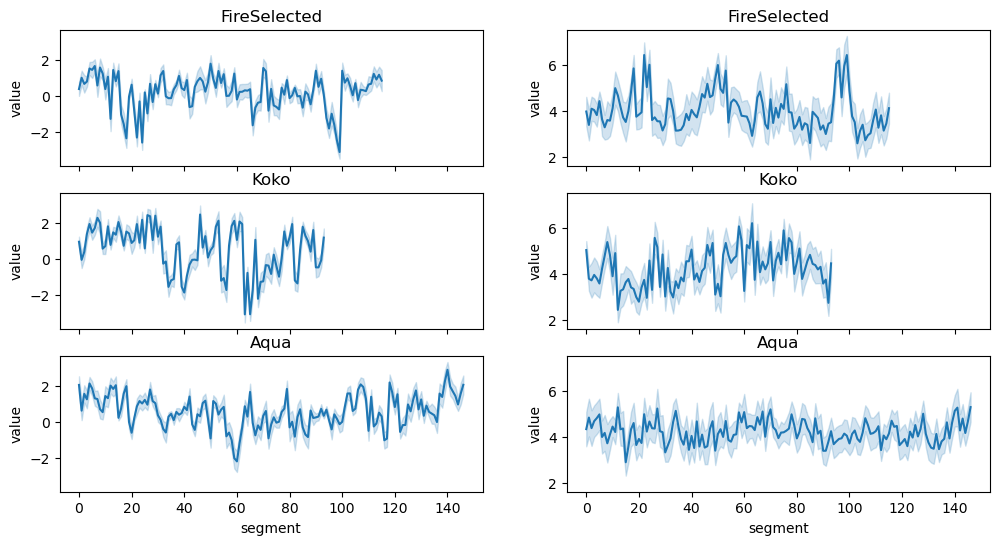

In [76]:
df_human = pd.read_csv(r'X:\PROJECTS\ABC@UofSC\3-Experiments\NSF_valence\github\derivatives\behavioral\ratings\qualtrics_sona\raw\rating_ABCNaturalisticNarrativeAudio_sona_A.csv')
df_human
List_story = df_human['story'].unique()
fig,axes = plt.subplots(nrows = len(List_story),ncols=2,figsize=(12,2*len(List_story)),sharex=True,sharey='col')
for i,story in enumerate(List_story):
    df_plot = df_human.loc[df_human['story']==story]
    sns.lineplot(data=df_plot.loc[df_plot['rating']=='V'],x='segment',y='value',ax=axes[i,0],errorbar='se').set_title(story)
    sns.lineplot(data=df_plot.loc[df_plot['rating']=='A'],x='segment',y='value',ax=axes[i,1],errorbar='se').set_title(story)


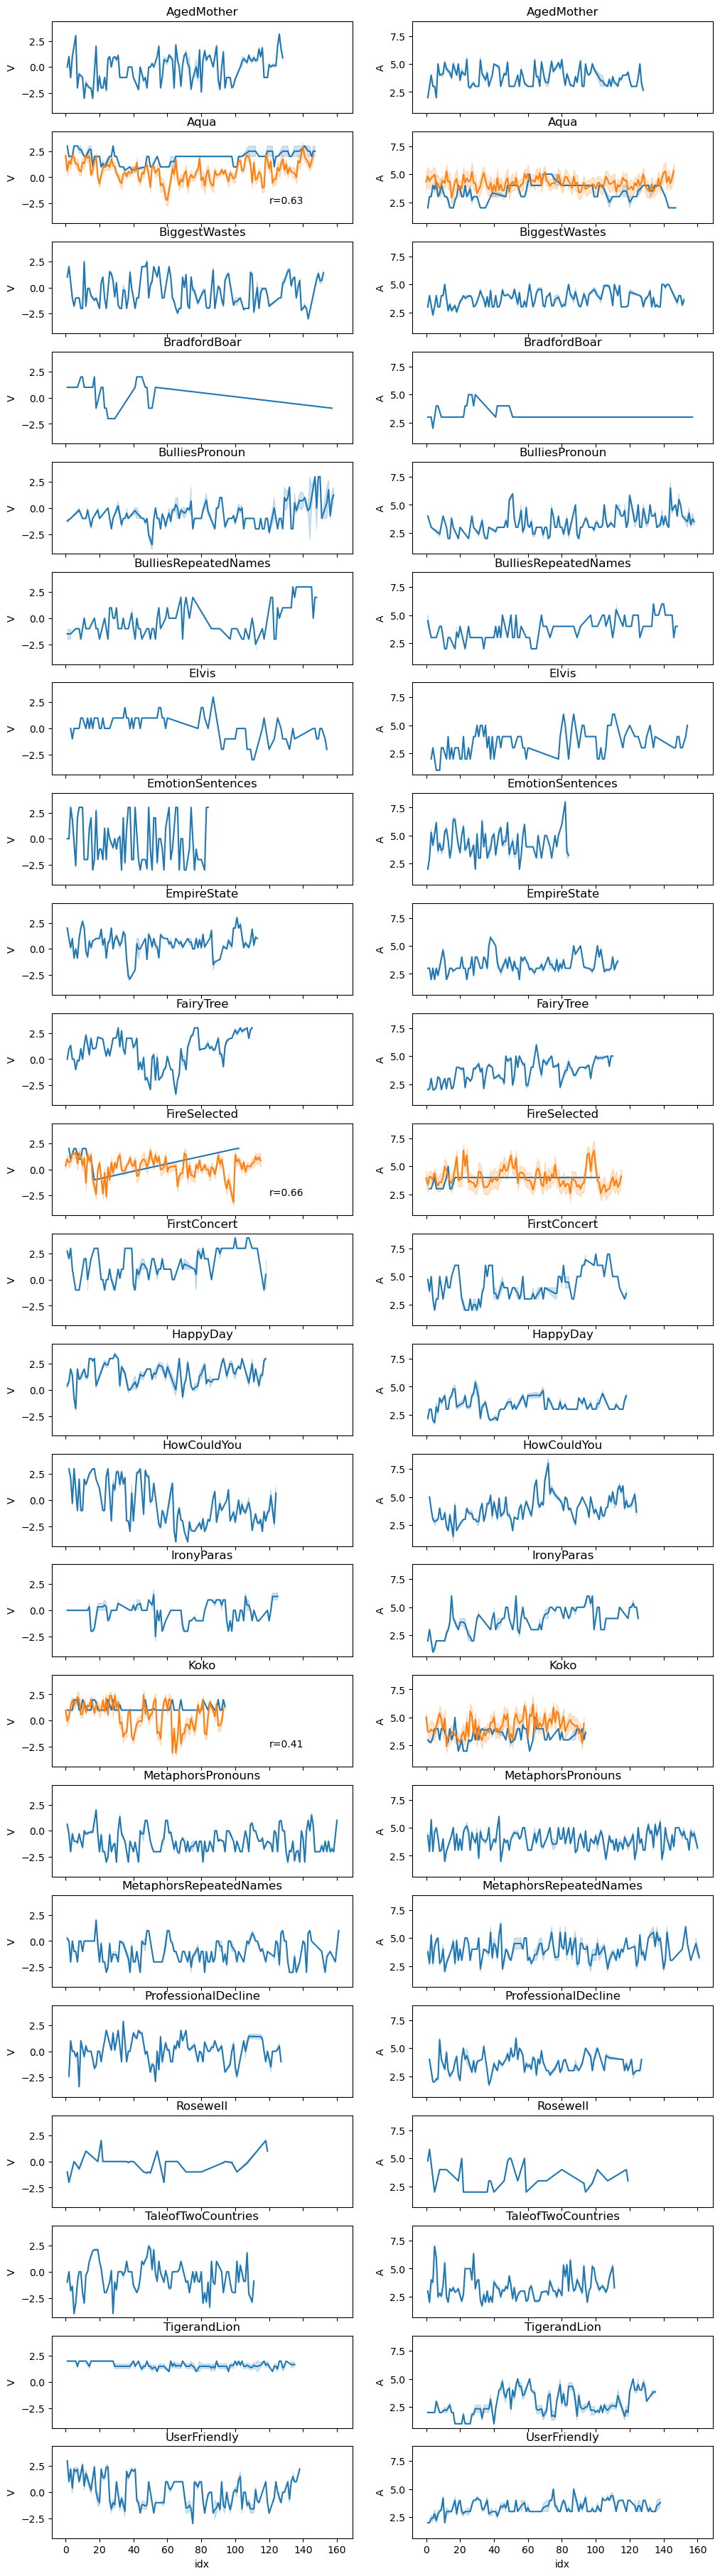

In [77]:
import scipy.stats

model = 'gpt-4-1106-preview'
# model = 'gpt-4o-2024-08-06'
dfs_score = pd.read_csv(os.path.join(Dir_results,f"rating_gpt_{model}.csv"))
df_mean_gpt = dfs_score.groupby(['story','idx']).mean().reset_index()
df_mean_human = df_human.loc[df_human['rating']=='V'].groupby(['story','segment']).mean().reset_index()

List_story = df_story['story'].values
fig,axes = plt.subplots(nrows = len(List_story),ncols=2,figsize=(12,2*len(List_story)),sharex=True,sharey='col')
for i,story in enumerate(List_story):
    df_plot = dfs_score.loc[dfs_score['story']==story]
    sns.lineplot(data=df_plot,x='idx',y='V',ax=axes[i,0],errorbar='se').set_title(story)
    sns.lineplot(data=df_plot,x='idx',y='A',ax=axes[i,1],errorbar='se').set_title(story)

    df_plot = df_human.loc[df_human['story']==story]
    if df_plot.shape[0] != 0:
            
        sns.lineplot(data=df_plot.loc[df_plot['rating']=='V'],x='segment',y='value',ax=axes[i,0],errorbar='se').set_title(story)
        sns.lineplot(data=df_plot.loc[df_plot['rating']=='A'],x='segment',y='value',ax=axes[i,1],errorbar='se').set_title(story)

        x = df_mean_gpt.loc[df_mean_gpt['story']==story,'V'].values
        y = df_mean_human.loc[df_mean_human['story']==story,'value'].values
        df_corr = pd.DataFrame({'x':x,'y':y}).dropna()
        result = scipy.stats.pearsonr(df_corr['x'], df_corr['y'])
        axes[i,0].text(x=120,y=-2.5,s=f"r={round(result.correlation,2)}")


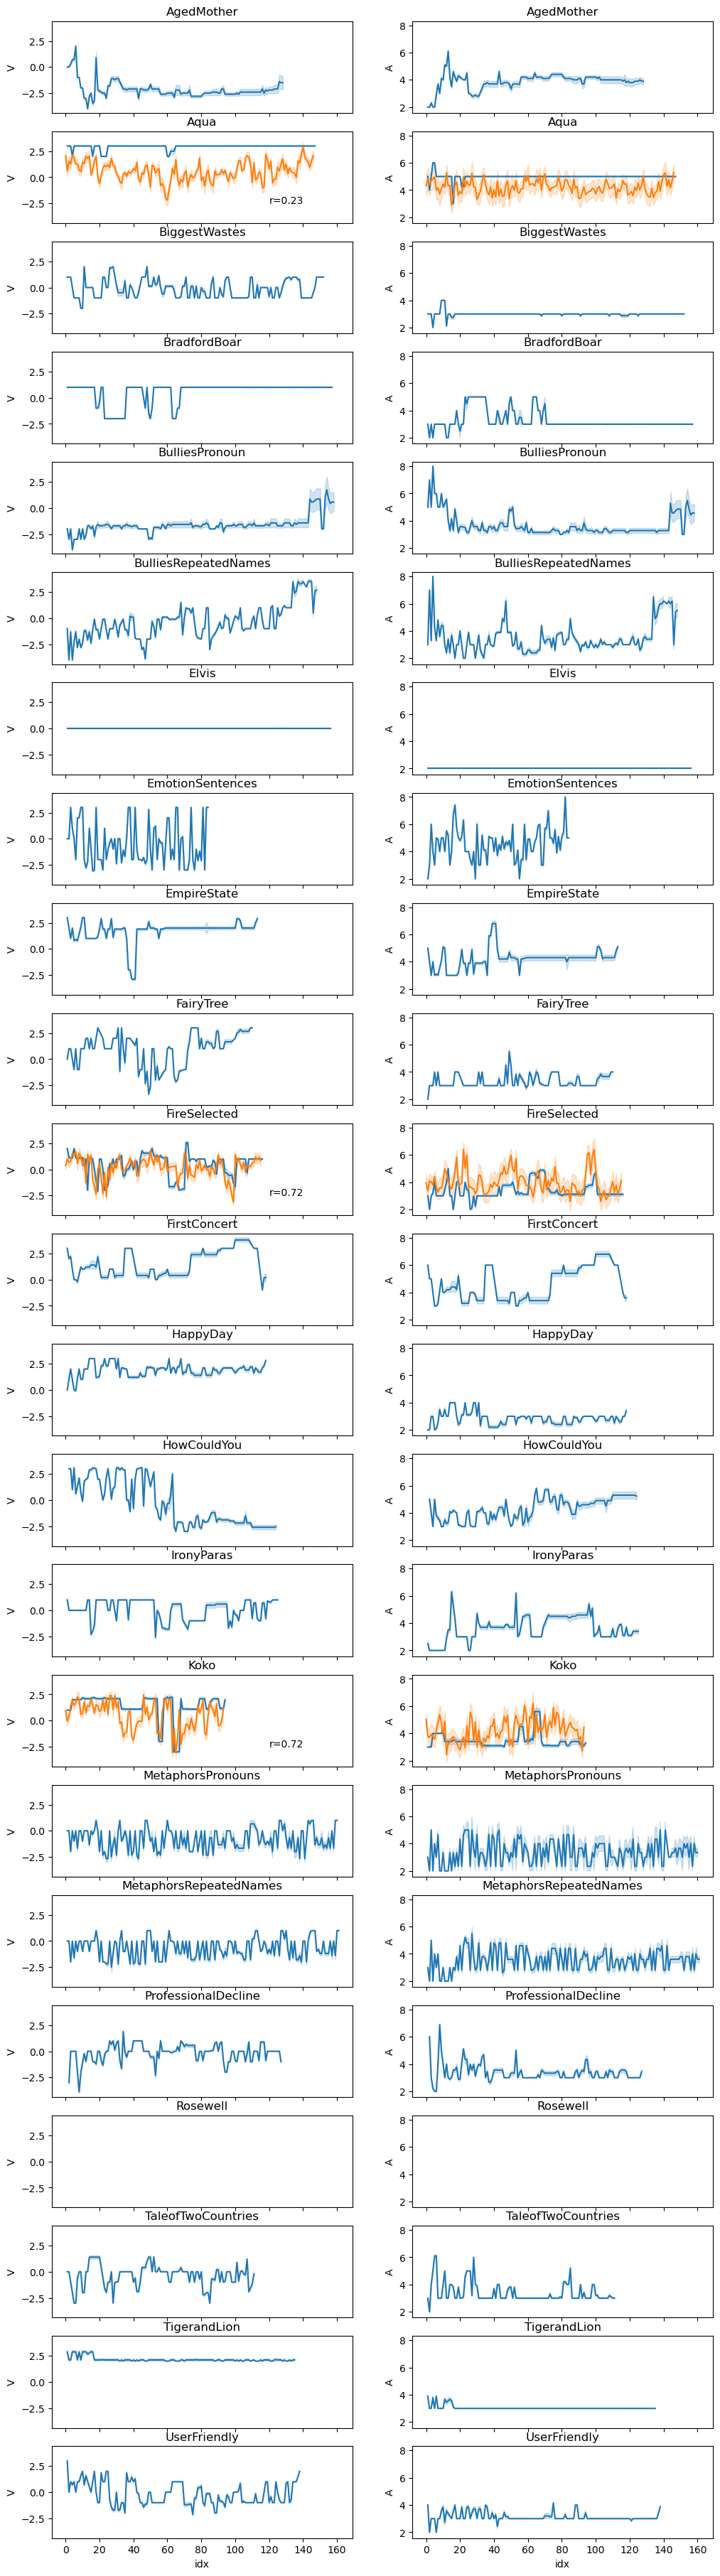

In [54]:
import scipy.stats

model = 'gpt-4o-2024-11-20'
# model = 'gpt-4o-2024-08-06'
dfs_score = pd.read_csv(os.path.join(Dir_results,f"rating_gpt_{model}.csv"))
df_mean_gpt = dfs_score.groupby(['story','idx']).mean().reset_index()
df_mean_human = df_human.loc[df_human['rating']=='V'].groupby(['story','segment']).mean().reset_index()

List_story = df_story['story'].values
fig,axes = plt.subplots(nrows = len(List_story),ncols=2,figsize=(12,2*len(List_story)),sharex=True,sharey='col')
for i,story in enumerate(List_story):
    df_plot = dfs_score.loc[dfs_score['story']==story]
    sns.lineplot(data=df_plot,x='idx',y='V',ax=axes[i,0],errorbar='se').set_title(story)
    sns.lineplot(data=df_plot,x='idx',y='A',ax=axes[i,1],errorbar='se').set_title(story)

    df_plot = df_human.loc[df_human['story']==story]
    if df_plot.shape[0] != 0:
            
        sns.lineplot(data=df_plot.loc[df_plot['rating']=='V'],x='segment',y='value',ax=axes[i,0],errorbar='se').set_title(story)
        sns.lineplot(data=df_plot.loc[df_plot['rating']=='A'],x='segment',y='value',ax=axes[i,1],errorbar='se').set_title(story)

        x = df_mean_gpt.loc[df_mean_gpt['story']==story,'V'].values
        y = df_mean_human.loc[df_mean_human['story']==story,'value'].values
        df_corr = pd.DataFrame({'x':x,'y':y}).dropna()
        result = scipy.stats.pearsonr(df_corr['x'], df_corr['y'])
        axes[i,0].text(x=120,y=-2.5,s=f"r={round(result.correlation,2)}")


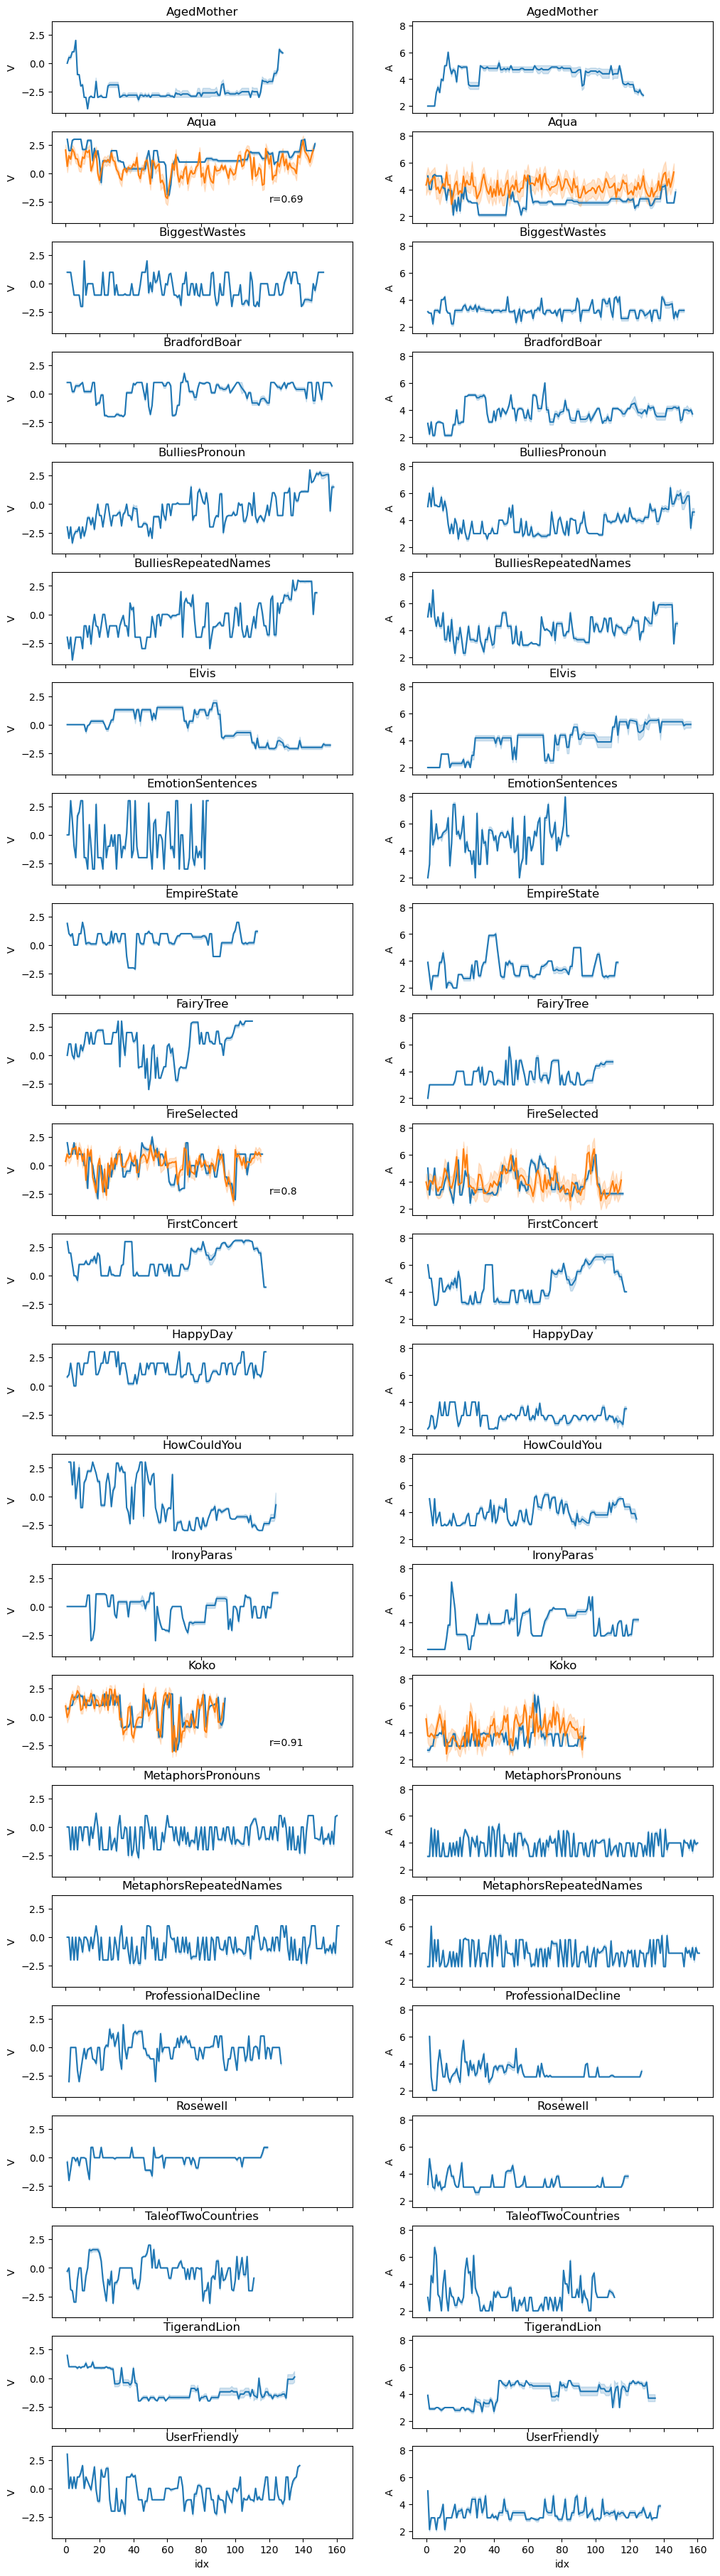

In [50]:
import scipy.stats

# model = 'gpt-4o-2024-11-20'
model = 'gpt-4o-2024-08-06'
dfs_score = pd.read_csv(os.path.join(Dir_results,f"rating_gpt_{model}.csv"))
df_mean_gpt = dfs_score.groupby(['story','idx']).mean().reset_index()
df_mean_human = df_human.loc[df_human['rating']=='V'].groupby(['story','segment']).mean().reset_index()

List_story = df_story['story'].values
fig,axes = plt.subplots(nrows = len(List_story),ncols=2,figsize=(12,2*len(List_story)),sharex=True,sharey='col')
for i,story in enumerate(List_story):
    df_plot = dfs_score.loc[dfs_score['story']==story]
    sns.lineplot(data=df_plot,x='idx',y='V',ax=axes[i,0],errorbar='se').set_title(story)
    sns.lineplot(data=df_plot,x='idx',y='A',ax=axes[i,1],errorbar='se').set_title(story)

    df_plot = df_human.loc[df_human['story']==story]
    if df_plot.shape[0] != 0:
            
        sns.lineplot(data=df_plot.loc[df_plot['rating']=='V'],x='segment',y='value',ax=axes[i,0],errorbar='se').set_title(story)
        sns.lineplot(data=df_plot.loc[df_plot['rating']=='A'],x='segment',y='value',ax=axes[i,1],errorbar='se').set_title(story)

        x = df_mean_gpt.loc[df_mean_gpt['story']==story,'V'].values
        y = df_mean_human.loc[df_mean_human['story']==story,'value'].values
        df_corr = pd.DataFrame({'x':x,'y':y}).dropna()
        result = scipy.stats.pearsonr(df_corr['x'], df_corr['y'])
        axes[i,0].text(x=120,y=-2.5,s=f"r={round(result.correlation,2)}")


In [15]:
dfs_score_summary = dfs_score.groupby(['story','idx']).mean().reset_index()
dfs_score_summary['iteration'] = dfs_score.groupby(['story','idx']).count().reset_index()['iteration']
dfs_score_summary

,story,idx,onset,offset,idx_raw,V,A,iteration
0,AgedMother,1,5.200000,6.36,0.0,0.000,2.000,10
1,AgedMother,2,6.650000,8.29,1.0,0.500,2.000,10
2,AgedMother,3,8.309999,11.07,2.0,0.500,2.000,10
3,AgedMother,4,12.080000,13.30,3.0,1.000,2.000,10
4,AgedMother,5,13.309999,14.79,4.0,1.000,2.000,10
...,...,...,...,...,...,...,...,...
2995,UserFriendly,134,350.349999,352.08,133.0,0.625,3.000,8
2996,UserFriendly,135,352.150000,357.66,134.0,0.875,3.000,8
2997,UserFriendly,136,357.770000,359.81,135.0,1.000,3.000,8
2998,UserFriendly,137,359.809999,NaN,136.0,1.875,3.875,8
